In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Types of Normaliztion
* MinMax Scaling
* Mean Normalization
* Maxabs Scaling
* Robust Scaling


In [2]:
df=pd.read_csv("/home/ammarkhalid/Machine Learning/100 days of Machine Learning/Normalization/Datasets/wine_data.csv")

In [3]:
df

,1,14.23,1.71,2.43,15.6,127,2.8,3.06,.28,2.29,5.64,1.04,3.92,1065
0,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
1,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
2,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
3,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
4,1,14.20,1.76,2.45,15.2,112,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,3,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
173,3,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
174,3,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
175,3,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


In [14]:
df=df.iloc[:,0:3]
df.rename(columns={'1':"Label",'14.23':"Alcohol",'1.71':"Malic Acid"},inplace=True)
df

,Label,Alcohol,Malic Acid
0,1,13.20,1.78
1,1,13.16,2.36
2,1,14.37,1.95
3,1,13.24,2.59
4,1,14.20,1.76
...,...,...,...
172,3,13.71,5.65
173,3,13.40,3.91
174,3,13.27,4.28
175,3,13.17,2.59


In [16]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(df.drop(columns=['Label']),df,test_size=0.2)
x_train.shape,x_test.shape

((141, 2), (36, 2))

### MinMax Scaling

In [17]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()

scaler.fit(x_train)
x_train_scaled=scaler.transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [19]:
x_train_scaled=pd.DataFrame(x_train_scaled,columns=x_train.columns)
x_test_scaled=pd.DataFrame(x_test_scaled,columns=x_test.columns)

In [22]:
np.round(x_train_scaled.describe()),np.round(x_test_scaled.describe())

(       Alcohol  Malic Acid
 count    141.0       141.0
 mean       1.0         0.0
 std        0.0         0.0
 min        0.0         0.0
 25%        0.0         0.0
 50%        1.0         0.0
 75%        1.0         0.0
 max        1.0         1.0,
        Alcohol  Malic Acid
 count     36.0        36.0
 mean       0.0         0.0
 std        0.0         0.0
 min        0.0         0.0
 25%        0.0         0.0
 50%        0.0         0.0
 75%        1.0         0.0
 max        1.0         1.0)

Text(0.5, 1.0, 'After Scaling')

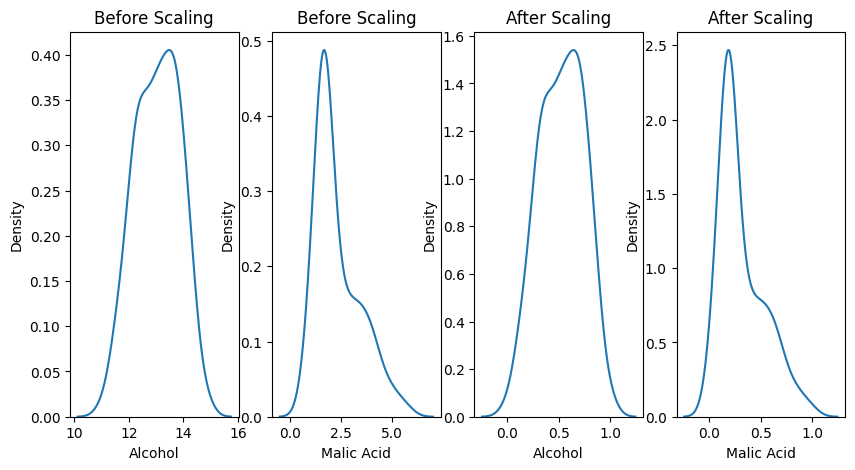

In [41]:
fig,axes=plt.subplots(1,4,figsize=(10,5))
sns.kdeplot(data=x_train,x='Alcohol',ax=axes[0])
sns.kdeplot(data=x_train,x='Malic Acid',ax=axes[1])
axes[0].set_title('Before Scaling')
axes[1].set_title('Before Scaling')
sns.kdeplot(data=x_train_scaled,x='Alcohol',ax=axes[2])
sns.kdeplot(data=x_train_scaled,x='Malic Acid',ax=axes[3])

axes[2].set_title('After Scaling')
axes[3].set_title('After Scaling')

#shape is almost always preserved, sometimes it may be changed

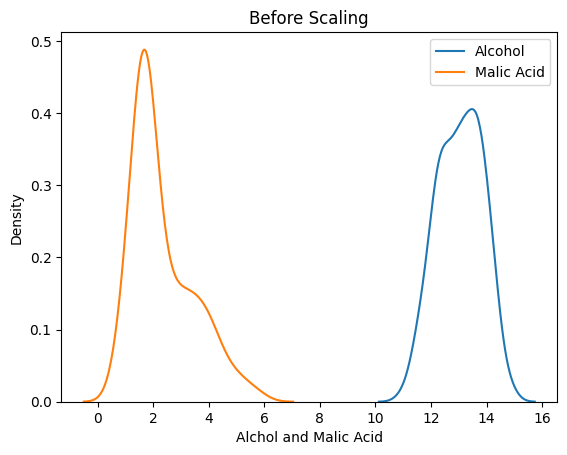

In [53]:
sns.kdeplot(x_train['Alcohol'],label='Alcohol')
sns.kdeplot(x_train['Malic Acid'],label='Malic Acid')
plt.title("Before Scaling")
plt.xlabel("Alchol and Malic Acid")
plt.legend()

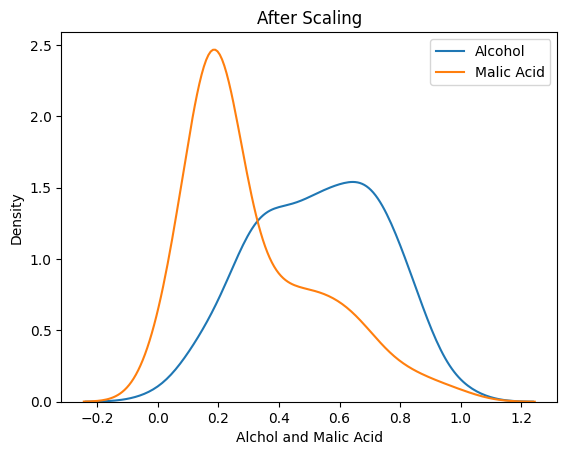

In [55]:
sns.kdeplot(x_train_scaled['Alcohol'],label='Alcohol')
sns.kdeplot(x_train_scaled['Malic Acid'],label='Malic Acid')
plt.title("After Scaling")
plt.xlabel("Alchol and Malic Acid")
plt.legend()
# now they are in same range of [0,1]

### Mean Normalization

In [71]:
def mean_normalization(x_train,x_test=None):
    normalized_x_train=(x_train - np.mean(x_train)) / (np.max(x_train) - np.min(x_train))

    if x_test is not None:
        normalized_x_test=(x_test - np.mean(x_train)) / (np.max(x_train) - np.min(x_train))
        return normalized_x_train,normalized_x_test
    return normalized_x_train

# Note: we are only computing the mean, min, max for the training data to avoid data leakage

In [73]:
x_train_scaled,x_test_scaled=mean_normalization(x_train,x_test)

In [76]:
x_train_scaled

,Alcohol,Malic Acid
34,0.411342,-0.416904
20,0.372308,-0.275670
25,0.404955,-0.419743
156,0.338241,-0.330318
119,0.267269,-0.375031
...,...,...
23,0.412762,-0.416904
112,0.264430,-0.492845
154,0.389341,-0.177018
141,0.414181,-0.320382


In [77]:
x_test_scaled

,Alcohol,Malic Acid
68,0.321208,-0.460907
158,0.411342,-0.426841
5,0.475927,-0.412646
89,0.311981,-0.415485
110,0.343209,-0.372902
133,0.342499,-0.457359
46,0.441151,-0.426131
98,0.326885,-0.320382
172,0.427666,-0.144371
21,0.427666,-0.413356


### Maxabs Scaling
best for sparse data (data with many zeros)

In [78]:
from sklearn.preprocessing import MaxAbsScaler
scaler=MaxAbsScaler()
scaler.fit(x_train)

x_train_scaled=scaler.transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [79]:
x_test.shape,x_train_scaled.shape

((36, 2), (141, 2))

In [81]:
x_train_scaled=pd.DataFrame(x_train_scaled,columns=x_train.columns)
x_test_scaled=pd.DataFrame(x_test_scaled,columns=x_test.columns)

### Robust Scaling

In [84]:
from sklearn.preprocessing import RobustScaler
scaler=RobustScaler()
scaler.fit(x_train)

x_train_scaled=scaler.transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [85]:
x_train_scaled=pd.DataFrame(x_train_scaled,columns=x_train.columns)
x_test_scaled=pd.DataFrame(x_test_scaled,columns=x_test.columns)

In [86]:
x_train_scaled.describe()

,Alcohol,Malic Acid
count,141.000000,141.000000
mean,-0.028100,0.320747
std,0.615384,0.781888
min,-1.553030,-0.795775
25%,-0.537879,-0.183099
50%,0.000000,0.000000
75%,0.462121,0.816901
max,1.325758,2.767606
